# Why we use charts in machine learning

Charts help us understand what is in our data, notice unusual values, and see how a model performs. This notebook looks at school data in three steps:

1. **Explore and prepare the data** - inspect the schools and choose useful columns.
2. **Study relationships** - compare school resources and outcomes.
3. **Try simple models** - evaluate a classifier and make a two-dimensional view of the data.

In [1]:
# Import pandas so we can work with table-shaped data.
import pandas as pd  # Give pandas the short name pd.
# Import NumPy for common numerical operations.
import numpy as np  # Give NumPy the short name np.
# Import Matplotlib's plotting interface for charts.
import matplotlib.pyplot as plt  # Give the plotting interface the short name plt.
# Import Seaborn for statistical charts built on Matplotlib.
import seaborn as sns  # Give Seaborn the short name sns.
# Tell pandas to show every column when it prints a table.
pd.set_option('display.max_columns', None)  # None means there is no display limit for columns.

In [2]:
# Read the CSV file in the notebook's folder into a pandas table called us_edu_data.
us_edu_data = pd.read_csv('us_education_system_dataset.csv')  # Load the school dataset.
# Display the first five rows so we can preview the data.
us_edu_data.head(5)  # The number 5 asks pandas for five rows.

,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,special_education_pct,english_learner_pct,per_pupil_expenditure_usd,federal_funding_pct,state_funding_pct,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,30,14.8,48.9,70.9,2.4,15.4,8.1,0.1,3.1,14.4,12.9,12840,15.0,54.8,30.2,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,29,10.0,1.2,34.7,8.6,36.1,13.3,1.3,6.0,13.7,19.3,17009,0.0,2.0,98.0,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,17,18.2,36.0,26.2,29.2,22.9,12.3,1.9,7.5,15.7,11.3,15374,10.7,55.5,33.8,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,34,11.3,15.1,49.2,16.7,4.3,26.4,0.1,3.3,13.8,9.8,17065,6.8,38.3,54.9,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,29,13.9,45.6,78.1,3.2,8.0,3.9,2.1,4.7,19.8,5.3,16823,15.0,42.3,42.7,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3


## What is in the dataset?

Each row describes a school. The columns cover its location and type, student and staff counts, student demographics, funding, academic outcomes, and technology access. We will first inspect the data, then focus on a smaller set of columns for the charts and model.

## Columns used in the examples

We keep a small group of columns to make the analysis easier to follow: school name, Title I status, school level, public/private control, spending per student, eligibility for free or reduced-price lunch, math proficiency, and graduation rate. These columns describe school context and two important outcomes.

In [3]:
# Select only the columns we need for the first set of charts.
us_edu_keymetrics_data = us_edu_data[[  # Save the selected columns in a smaller table.
    'institution_name',  # Keep the school's name for identification.
    'title_i_status',  # Keep whether the school has Title I status.
    'level',  # Keep the school's grade or school level.
    'control',  # Keep whether the school is public or private.
    'per_pupil_expenditure_usd',  # Keep spending per student in dollars.
    'percent_free_reduced_lunch',  # Keep the share eligible for meal assistance.
    'math_proficiency_pct',  # Keep the math proficiency percentage.
    'graduation_rate_pct'  # Keep the graduation rate percentage.
]]  # Close the list of selected columns and finish the selection.

In [4]:
# Preview the first five rows of the smaller table.
us_edu_keymetrics_data.head()  # Display the selected school metrics.

,institution_name,title_i_status,level,control,per_pupil_expenditure_usd,percent_free_reduced_lunch,math_proficiency_pct,graduation_rate_pct
0,Jefferson Elementary School,Title I Schoolwide,Elementary School,Public,12840,48.9,58.3,80.9
1,Lakeshore Middle School,Not Applicable,Middle School,Private Religious,17009,1.2,84.8,93.5
2,Meadowbrook Elementary Academy,Not Applicable,Elementary School,Private For-Profit,15374,36.0,54.6,80.2
3,Roosevelt Primary School,Not Title I Eligible,Elementary School,Public,17065,15.1,66.1,82.1
4,Highland Park Primary School,Title I Targeted,Elementary School,Public,16823,45.6,54.6,90.2


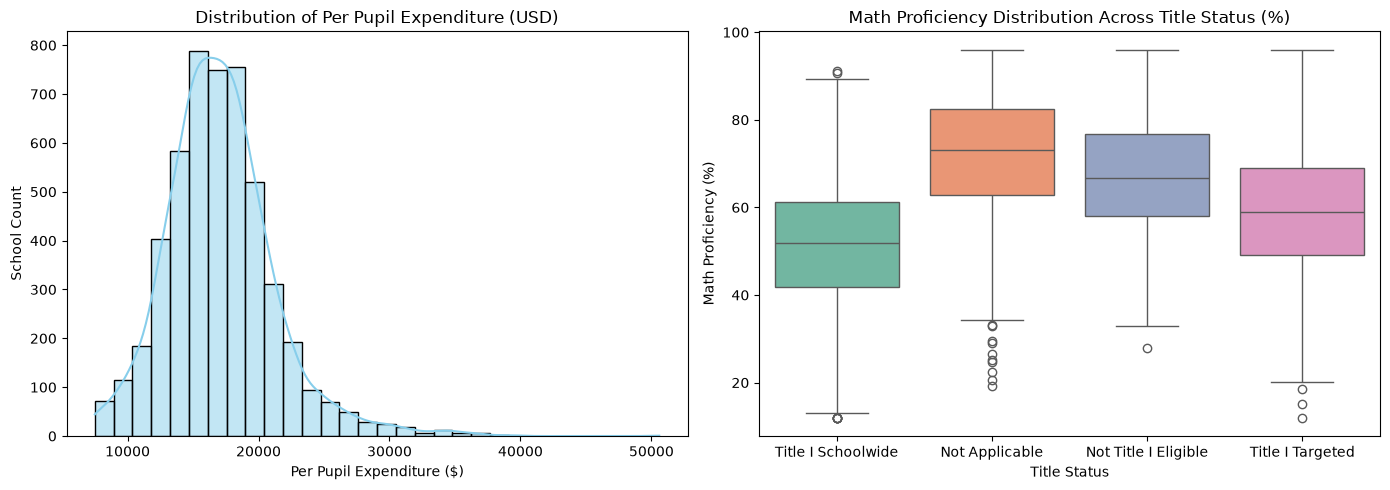

In [5]:
# Create one figure that will contain two charts side by side.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # Make one row, two columns of plotting areas.

# Draw a histogram of spending per student, including a smoothed density curve.
sns.histplot(us_edu_keymetrics_data['per_pupil_expenditure_usd'], kde=True, ax=axes[0], color='skyblue', bins=30)  # Use 30 bars in the left plotting area.
# Add a descriptive title to the spending chart.
axes[0].set_title('Distribution of Per Pupil Expenditure (USD)')  # Explain what the chart shows.
# Label the spending chart's horizontal axis.
axes[0].set_xlabel('Per Pupil Expenditure ($)')  # Values are dollars spent per student.
# Label the spending chart's vertical axis.
axes[0].set_ylabel('School Count')  # Bar heights count schools.

# Compare math proficiency across Title I categories with box plots.
sns.boxplot(data=us_edu_keymetrics_data, x='title_i_status', y='math_proficiency_pct', hue='title_i_status', legend=False, ax=axes[1], palette='Set2')  # Draw the comparison in the right plotting area.
# Add a descriptive title to the math chart.
axes[1].set_title('Math Proficiency Distribution Across Title Status (%)')  # Explain what the chart compares.
# Label the math chart's horizontal axis.
axes[1].set_xlabel('Title Status')  # Categories identify Title I status.
# Label the math chart's vertical axis.
axes[1].set_ylabel('Math Proficiency (%)')  # Values are proficiency percentages.

# Adjust spacing so chart labels do not overlap.
plt.tight_layout()  # Fit the charts and labels neatly in the figure.
# Display both charts.
plt.show()  # Render the figure in the notebook.

## Reading the first charts

The histogram shows how much schools spend per student and whether the values cluster or include unusually high or low amounts. The box plot compares math proficiency across Title I groups. A chart can reveal patterns, but it does not by itself explain why they occur.

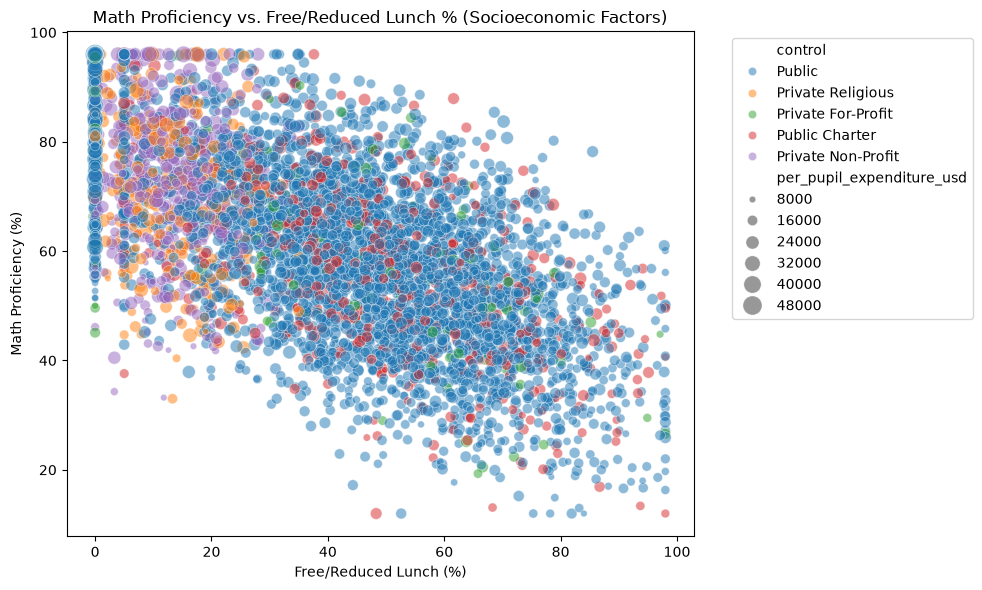

In [6]:
# Set the size of the figure before drawing the scatter plot.
plt.figure(figsize=(10, 6))  # Make the chart wide enough to read.

# Plot meal-assistance eligibility against math proficiency.
sns.scatterplot(data=us_edu_keymetrics_data, x='percent_free_reduced_lunch',  # Put meal-assistance percentage on the horizontal axis.
                y='math_proficiency_pct', hue='control',  # Put math proficiency on the vertical axis and color by school control.
                size='per_pupil_expenditure_usd',  # Use marker size to show spending per student.
                sizes=(20, 200),  # Map spending values to marker sizes from 20 to 200.
                alpha=0.5)  # Make markers partly transparent where points overlap.

# Give the chart a title that describes its comparison.
plt.title('Math Proficiency vs. Free/Reduced Lunch % (Socioeconomic Factors)')  # Summarize the variables shown.
# Label the horizontal axis.
plt.xlabel('Free/Reduced Lunch (%)')  # Identify the meal-assistance percentage.
# Label the vertical axis.
plt.ylabel('Math Proficiency (%)')  # Identify the math proficiency percentage.
# Place the legend outside the chart so it is easier to read.
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Move the legend to the right.
# Adjust spacing so the chart and its legend fit.
plt.tight_layout()  # Apply the layout adjustment (the parentheses run the function).
# Display the scatter plot.
plt.show()  # Render the figure in the notebook.

## Exploring links between school measures

The next charts look at how numeric school resources and outcomes move together. Before calculating relationships, we will check the dataset's column types and choose numeric measures.

## Correlation heatmap

A correlation heatmap summarizes how pairs of numeric measures move together. Values near 1 suggest they tend to rise together, values near -1 suggest one tends to rise as the other falls, and values near 0 suggest a weaker straight-line relationship. Correlation does not prove that one measure causes another.

In [7]:
# Print each column's data type and count of non-missing values.
us_edu_data.info()  # This helps us understand the table before analysis.

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 35 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   institution_id                5000 non-null   str    
 1   institution_name              5000 non-null   str    
 2   state_code                    5000 non-null   str    
 3   state_name                    5000 non-null   str    
 4   county                        5000 non-null   str    
 5   nces_locale                   5000 non-null   str    
 6   level                         5000 non-null   str    
 7   control                       5000 non-null   str    
 8   title_i_status                5000 non-null   str    
 9   total_enrollment              5000 non-null   int64  
 10  number_of_teachers            5000 non-null   int64  
 11  student_teacher_ratio         5000 non-null   float64
 12  percent_free_reduced_lunch    5000 non-null   float64
 13  racial_white_p

## Choose numeric measures

We will compare spending, class resources, student needs, and school outcomes. The next code cell lists the numeric columns used to calculate correlations.

In [8]:
# List the numeric columns that describe resources and school outcomes.
numeric_cols = [  # Store the selected column names in a Python list.
    'per_pupil_expenditure_usd',  # Spending for each student in dollars.
    'student_teacher_ratio',  # Number of students per teacher.
    'percent_free_reduced_lunch',  # Share of students eligible for meal assistance.
    'special_education_pct',  # Share of students receiving special education.
    'english_learner_pct',  # Share of students learning English.
    'math_proficiency_pct',  # Share meeting the math proficiency measure.
    'reading_proficiency_pct',  # Share meeting the reading proficiency measure.
    'graduation_rate_pct',  # Share of students who graduate.
    'chronic_absenteeism_pct'  # Share with chronic absenteeism.
]  # Finish the list of selected numeric columns.

In [9]:
# Calculate correlations between the selected numeric columns.
corr_matrix = us_edu_data[numeric_cols].corr()  # Store the pairwise correlations in a table.

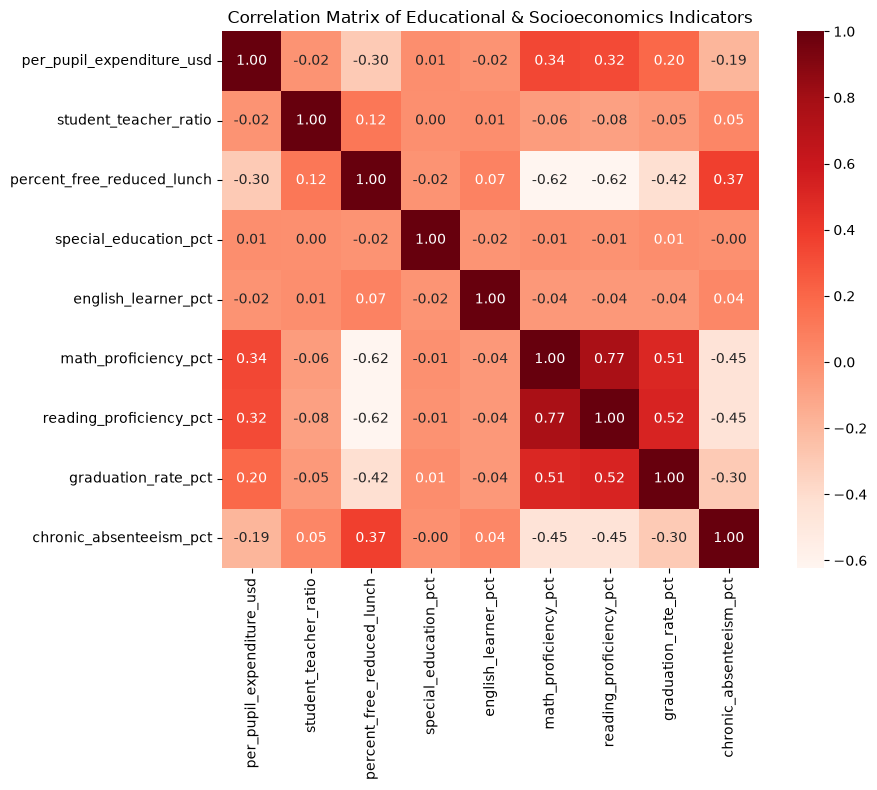

In [10]:
# Start a figure that is ten inches wide and eight inches tall.
plt.figure(figsize=(10, 8))  # Make room for the heatmap labels.

# Draw the correlation values as a colored heatmap.
sns.heatmap(corr_matrix, annot=True, cmap='Reds', square=True, fmt='.2f', cbar=True)  # Print each value to two decimal places.
# Add a title explaining the measures in the heatmap.
plt.title('Correlation Matrix of Educational & Socioeconomics Indicators')  # Describe the chart.
# Adjust spacing so the title and labels fit.
plt.tight_layout()  # Apply the spacing adjustment.
# Display the heatmap.
plt.show()  # Render the figure in the notebook.

## A simple model check

We will train a classifier to sort schools into two groups: math proficiency at or above the dataset median, or below it. The model uses other numeric measures. A confusion matrix counts correct and incorrect predictions; this small example demonstrates the process and does not show that the inputs cause the outcome.

In [11]:
# Import the function that divides data into training and test groups.
from sklearn.model_selection import train_test_split  # Use separate data to train and check the model.
# Import a collection of decision trees for classification.
from sklearn.ensemble import RandomForestClassifier  # This model combines many decision trees.
# Import a function that counts correct and incorrect class predictions.
from sklearn.metrics import confusion_matrix  # Use it to summarize model predictions.

In [12]:
# Keep rows that have values in every selected numeric column.
data_clean = us_edu_data[numeric_cols].dropna()  # Remove incomplete rows for this model example.

In [13]:
# Create the model inputs by removing math proficiency from the selected columns.
X = data_clean.drop(columns=['math_proficiency_pct'])  # X contains the features used to make predictions.
# Mark schools at or above the median math score as 1, and those below it as 0.
y = (data_clean['math_proficiency_pct'] >= data_clean['math_proficiency_pct'].median()).astype(int)  # y contains the two target groups.
# Preview the first five target labels.
y.head()  # Show whether each sample is in group 0 or group 1.

0    0
1    1
2    0
3    1
4    0
Name: math_proficiency_pct, dtype: int64

In [14]:
# Split the features and labels into training and test groups.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)  # Use 70% to train and 30% to test, with a repeatable split.

In [15]:
# Create a random-forest classifier with 100 decision trees.
clf = RandomForestClassifier(n_estimators=100, random_state=42)  # Fix the random seed so results can be repeated.
# Teach the classifier using the training features and their known labels.
clf.fit(X_train, y_train)  # The model learns patterns from the training data.
# Predict the labels for the held-back test features.
y_pred = clf.predict(X_test)  # These predictions can be compared with the true test labels.

In [16]:
# Count the true and predicted labels in a confusion matrix.
cm = confusion_matrix(y_test, y_pred)  # Rows are true classes and columns are predicted classes.

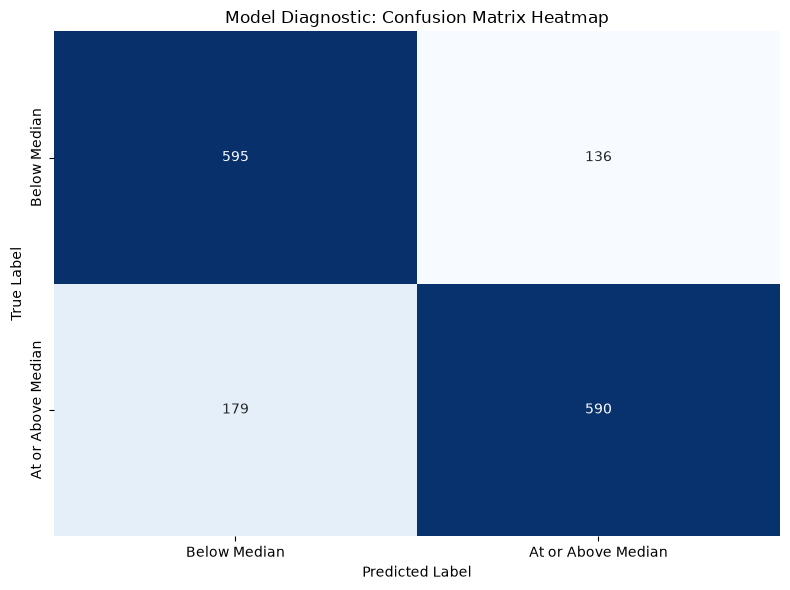

In [17]:
# Start a figure for the model's confusion matrix.
plt.figure(figsize=(8, 6))  # Make the chart large enough to read.
# Draw the counts as a blue heatmap with class names on both axes.
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,  # Show each count as an integer and hide the color scale.
            xticklabels=['Below Median', 'At or Above Median'],  # Name the prediction categories.
            yticklabels=['Below Median', 'At or Above Median'])  # Name the true categories.
# Label the horizontal axis with the model's predictions.
plt.xlabel('Predicted Label')  # These are the groups chosen by the model.
# Label the vertical axis with the actual groups.
plt.ylabel('True Label')  # These are the known groups from the dataset.
# Give the chart a clear title.
plt.title('Model Diagnostic: Confusion Matrix Heatmap')  # Identify what the chart measures.
# Adjust spacing so labels fit.
plt.tight_layout()  # Apply the spacing adjustment.
# Display the confusion matrix.
plt.show()  # Render the figure in the notebook.

## Reduce the data to two dimensions

Many measures are hard to view all at once. Principal component analysis (PCA) combines the standardized numeric columns into two new axes so we can draw a simple scatter plot. The two axes summarize variation in the original columns; they are not individual school measures.

## PCA view

The next cells scale the numeric columns to comparable ranges, calculate two principal components, and plot each school as a point. The axis labels show how much of the dataset's variation each component represents.

In [18]:
# Import PCA to reduce many numeric features to a smaller number of dimensions.
from sklearn.decomposition import PCA  # PCA finds new axes that summarize variation.
# Import a scaler to put numeric columns on comparable scales.
from sklearn.preprocessing import StandardScaler  # Scaling prevents large-unit columns from dominating PCA.

In [19]:
# Create a scaler that will standardize each feature.
scaler = StandardScaler()  # Standardization centers and rescales each column.
# Fit the scaler to the features and transform them to standardized values.
X_scaled = scaler.fit_transform(X)  # Each feature is now on a comparable scale.

In [20]:
# Create a PCA model that will keep two components.
pca = PCA(n_components=2)  # Reduce the feature set to two dimensions.
# Fit PCA to the scaled features and calculate each school's two coordinates.
X_pca = pca.fit_transform(X_scaled)  # Store the two-dimensional representation.

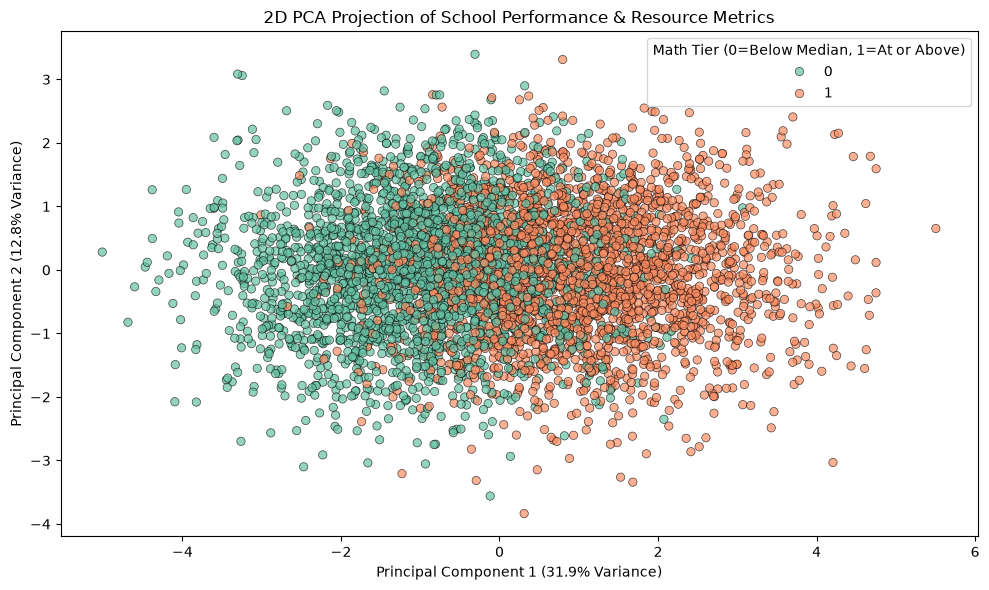

In [21]:
# Start a figure for the two-dimensional PCA scatter plot.
plt.figure(figsize=(10, 6))  # Make the chart wide enough to read.
# Plot each school using its first two principal-component coordinates.
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='Set2', alpha=0.7,  # Color points by the target group.
                edgecolors='k', linewidth=0.5)  # Outline points so they remain visible.

# Label the first axis with the share of variation it captures.
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0] * 100:.1f}% Variance)')  # Show the percentage to one decimal place.
# Label the second axis with the share of variation it captures.
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1] * 100:.1f}% Variance)')  # Show the percentage to one decimal place.
# Add a title that describes the two-dimensional view.
plt.title('2D PCA Projection of School Performance & Resource Metrics')  # Describe the data shown.
# Explain that 0 and 1 identify the two math-performance groups.
plt.legend(title='Math Tier (0=Below Median, 1=At or Above)', loc='upper right')  # Place the legend inside the upper-right corner.
# Adjust spacing so the labels and chart fit.
plt.tight_layout()  # Apply the spacing adjustment.
# Display the PCA scatter plot.
plt.show()  # Render the figure in the notebook.